# 3D FDTD: a dielectric sphere against Mie theory, and the photonic nanojet

The FDTD notebooks so far ([57](57_fdtd_basics.ipynb) to
[63](63_fdtd_devices.ipynb)) were 1D and 2D: structures infinitely long
along z. This one goes 3D, with all six field components:

1. the **Yee cell in 3D** and what a 3D run costs,
2. a **dielectric sphere** in a plane wave against the exact vector
   **Mie series** (`analytical.mie_field`): near field and scattering
   cross section over a band, from one pulsed run (validation V8 of
   proposals/fdtd.md),
3. the **photonic nanojet**: a glass microsphere a few wavelengths across
   focuses light into a narrow jet right behind its surface, much closer
   than ray optics predicts and narrower across the polarization than
   along it. FDTD, Mie, rays, the scalar sphere series and the WPM of
   notebook [05](05_WPM.ipynb) side by side.

Lengths are in units of the vacuum wavelength λ (or in µm for λ = 1 µm).
The 3D runs use the numba kernels (`pip install pyoptics[fast]`); with
NumPy alone they work but take about ten times longer.

In [1]:
import os
import tempfile
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.special import j0

from pyoptics import fdtd
from pyoptics import analytical as an
from pyoptics.fdtd import plot as fplot
from pyoptics.wpm import wpm_propagate
from pyoptics.utils import grid1d

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
print("numba kernels available:", fdtd.numba_available)
t_start = time.perf_counter()

numba kernels available: True


## 1. The Yee cell in 3D

In 3D, E and H each have three components, staggered by half a cell so
that every component is surrounded by the four components of the other
field whose curl it needs. With E sampled along the **edges** of a cell
and H at the centres of its **faces**:

| component | Ex | Ey | Ez | Hx | Hy | Hz |
|---|---|---|---|---|---|---|
| offset (cells) | (½, 0, 0) | (0, ½, 0) | (0, 0, ½) | (0, ½, ½) | (½, 0, ½) | (½, ½, 0) |

The 2D modes are slices of this cell: the Ez mode keeps Ez, Hx and Hy
(the vertical edge and the side faces), the Hz mode Ex, Ey and Hz. The
update equations are the curl equations
$\partial_t \mathbf H = -\nabla\times\mathbf E$,
$\varepsilon\,\partial_t \mathbf E = \nabla\times\mathbf H$, each
derivative a difference of two neighbours.

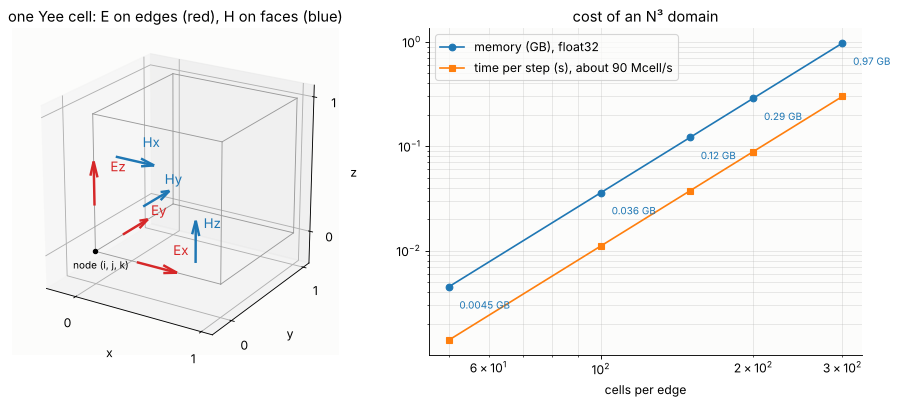

In [2]:
fig = plt.figure(figsize=(12, 5.2))
ax = fig.add_subplot(1, 2, 1, projection="3d")
for s, e in [((0, 0, 0), (1, 0, 0)), ((0, 0, 0), (0, 1, 0)), ((0, 0, 0), (0, 0, 1)),
             ((1, 0, 0), (1, 1, 0)), ((1, 0, 0), (1, 0, 1)), ((0, 1, 0), (1, 1, 0)),
             ((0, 1, 0), (0, 1, 1)), ((0, 0, 1), (1, 0, 1)), ((0, 0, 1), (0, 1, 1)),
             ((1, 1, 0), (1, 1, 1)), ((1, 0, 1), (1, 1, 1)), ((0, 1, 1), (1, 1, 1))]:
    ax.plot(*zip(s, e), color="0.6", lw=0.8)
L = 0.32
for name, p, d in [("Ex", (0.5, 0, 0), (1, 0, 0)), ("Ey", (0, 0.5, 0), (0, 1, 0)),
                   ("Ez", (0, 0, 0.5), (0, 0, 1))]:
    ax.quiver(*(np.array(p) - L/2*np.array(d)), *(L*np.array(d)), color="C3", lw=2.2,
              arrow_length_ratio=0.35)
    ax.text(*(np.array(p) + 0.08), name, color="C3", fontsize=12)
for name, p, d in [("Hx", (0, 0.5, 0.5), (1, 0, 0)), ("Hy", (0.5, 0, 0.5), (0, 1, 0)),
                   ("Hz", (0.5, 0.5, 0), (0, 0, 1))]:
    ax.quiver(*(np.array(p) - L/2*np.array(d)), *(L*np.array(d)), color="C0", lw=2.2,
              arrow_length_ratio=0.35)
    ax.text(*(np.array(p) + np.array([0.04, 0.04, 0.1])), name, color="C0", fontsize=12)
ax.scatter([0], [0], [0], color="k", s=15)
ax.text(-0.12, -0.1, -0.12, "node (i, j, k)", fontsize=9)
ax.set(xlabel="x", ylabel="y", zlabel="z", xticks=[0, 1], yticks=[0, 1], zticks=[0, 1],
       title="one Yee cell: E on edges (red), H on faces (blue)")
ax.view_init(22, -58)
ax.set_box_aspect((1, 1, 1))

# what a cubic domain costs: fields (6), update coefficients (3) and the CPML
b = fig.add_subplot(1, 2, 2)
n_cells = np.array([50, 100, 150, 200, 300])
mem = 9*4*n_cells**3/1e9                  # float32
b.loglog(n_cells, mem, "o-", label="memory (GB), float32")
b.loglog(n_cells, n_cells**3/90e6, "s-", label="time per step (s), about 90 Mcell/s")
for n_, m_ in zip(n_cells, mem):
    b.text(n_*1.05, m_*0.62, "%.2g GB" % m_, fontsize=9, color="C0")
b.set(xlabel="cells per edge", title="cost of an N³ domain")
b.legend(loc="upper left")
b.grid(alpha=0.3, which="both")
plt.tight_layout()

At 30 cells per wavelength, a box 5 wavelengths across has 150³ = 3.4
million cells: 120 MB and about 40 ms per step on four cores, so a run of
2000 steps takes about a minute and a half. Every halving of the cell size
costs 16 times more (8 times the cells, twice the steps). This is why 3D
runs use float32 by default (`Simulation(dtype=...)` overrides it), keep
the CPML auxiliary fields only inside the absorbing layers, sub-sample
the permittivity only in the cells a material boundary crosses, and why
the monitors below record planes rather than volumes.

## 2. A dielectric sphere against the Mie series

The scattering of a plane wave by a homogeneous sphere has an exact
solution: the Lorenz-Mie series of vector spherical harmonics (Bohren and
Huffman, chapter 4). `analytical.mie_coefficients` gives its
coefficients $a_n, b_n$ (scattered field) and $c_n, d_n$ (inside),
`analytical.mie_field` the electric field anywhere for an incident wave
$\mathbf E = \hat x\, e^{ikz}$, and `analytical.mie_efficiencies` the
extinction and scattering efficiencies. (`analytical.sphere_field` of
notebook 05 is the *scalar* counterpart, which knows nothing of the
polarization.) A first check, the example of Bohren and Huffman's
appendix:

In [3]:
q_ext, q_sca = an.mie_efficiencies(0.525, 1.55, 0.6328)
print("Q_ext = %.5f (Bohren & Huffman: 3.10543)" % q_ext)

Q_ext = 3.10543 (Bohren & Huffman: 3.10543)


The FDTD set-up: a sphere of radius 0.5 (diameter one wavelength at
λ = 1) and index 1.5, lit by a pulsed plane wave travelling along +z,
polarized along x. The plane wave enters through the surface of a
**TFSF box** (notebook 57) that holds the total field; outside it, only
the scattered field remains. A closed surface of six **flux planes**
outside the box collects the scattered power. With `TFSF(wavelengths=...)`
the source records the spectrum of the incident wave, which turns the
DFT fields of a pulse into fields per unit incident amplitude, for many
wavelengths at once. DFT monitors record the fields on the plane y = 0
inside the box, and a `Snapshots` monitor streams the time evolution of Ex on that plane
to an HDF5 file.

Grid(shape=(96, 96, 96), spacing=(np.float64(0.03333333333333333), np.float64(0.03333333333333333), np.float64(0.03333333333333333)), origin=(np.float64(-1.6), np.float64(-1.6), np.float64(-1.6))) 0.88 million cells


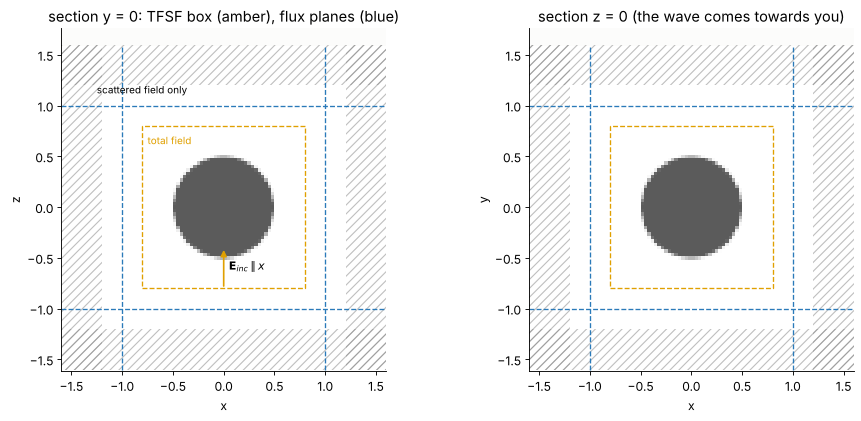

In [4]:
R1, N1, H1 = 0.5, 1.5, 1/30
WLS = np.linspace(0.7, 1.6, 31)          # cross sections
WL_MAP = np.array([0.8, 1.0, 1.25])      # field maps
D = 0.8                                    # TFSF half size
F = 1.0                                    # flux box half size
L1 = 2*1.2 + 24*H1
src1 = fdtd.TFSF((-D, D)*3, fdtd.GaussianPulse(1.0, 0.3), wavelengths=np.r_[WLS, WL_MAP])
dft1 = fdtd.DFTField(WL_MAP, components=["Ex", "Ey", "Ez"], region=((-0.75, 0.75), 0.0, (-0.75, 0.75)))
flux1 = [fdtd.Flux(s*F, WLS, axis=a, extent=((-F, F), (-F, F))) for a in range(3) for s in (-1, 1)]
h5 = os.path.join(tempfile.mkdtemp(), "sphere_xz.h5")
snap1 = fdtd.Snapshots("Ex", every=8, region=((-1.15, 1.15), 0.0, (-1.15, 1.15)), path=h5)
sphere = fdtd.Simulation(fdtd.Grid((L1, L1, L1), H1),
                         [(fdtd.Sphere((0, 0, 0), R1), fdtd.Medium.from_index(N1))],
                         [src1], [dft1, snap1] + flux1, boundaries=fdtd.PML(12))
print(sphere.grid, "%.2f million cells" % (np.prod(sphere.grid.shape)/1e6))

fig, ax = plt.subplots(1, 2, figsize=(12, 5.4))
fplot.plot_structure(sphere, ax=ax[0])
ax[0].set_title("section y = 0: TFSF box (amber), flux planes (blue)")
ax[0].text(-0.75, 0.62, "total field", color=fplot.SOURCE_COLOR, fontsize=9)
ax[0].text(-1.25, 1.12, "scattered field only", fontsize=9)
ax[0].text(0.05, -0.62, r"$\mathbf{E}_{inc} \parallel x$", fontsize=10)
fplot.plot_structure(sphere, ax=ax[1], plane=("z", 0.0))
ax[1].set_title("section z = 0 (the wave comes towards you)")
plt.tight_layout()

In [5]:
t0 = time.perf_counter()
sphere.run(time=32, progress=True)
z0 = sphere.grid.axis(2)[src1.box_indices[4]]
wl_all = np.r_[WLS, WL_MAP]
A1 = src1.incident_phasor(z0)*np.exp(-2j*np.pi/wl_all*z0)     # incident amplitude at z = 0
A_cs, A_map = A1[:len(WLS)], A1[len(WLS):]

1680 steps in 40.10 s (37.1 Mcell updates/s)


The field maps: $|\mathbf E|^2$ on the plane y = 0 (the plane of
polarization), all three components moved to common nodes with
`DFTField.colocated`, against the Mie series on the same nodes.

λ = 0.80: field error 4.6 % (all nodes), 3.1 % (more than 2 cells from the surface)
λ = 1.00: field error 3.5 % (all nodes), 1.6 % (more than 2 cells from the surface)
λ = 1.25: field error 3.1 % (all nodes), 0.9 % (more than 2 cells from the surface)


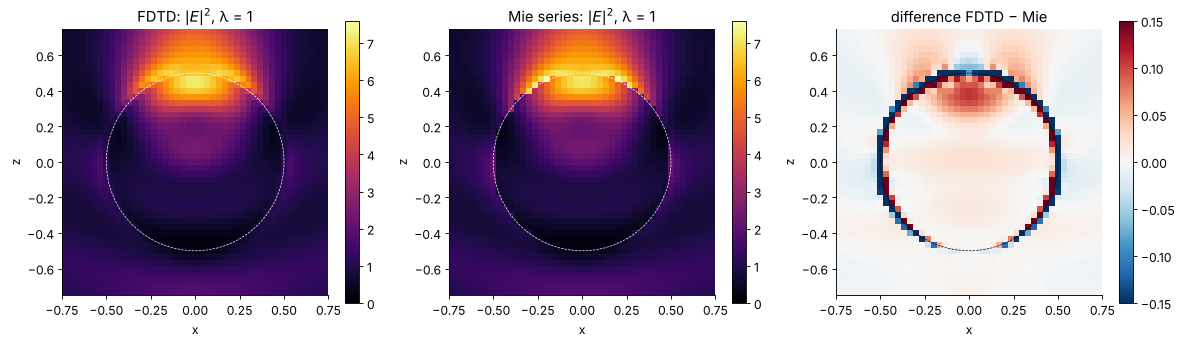

In [6]:
(xm, _, zm), Em = dft1.colocated(["Ex", "Ey", "Ez"], wavelength_index=1)
I_fd = np.sum(np.abs(Em[:, :, 0, :]/A_map[1])**2, axis=0)
X, Z = np.meshgrid(xm, zm, indexing="ij")
I_mie = np.sum(np.abs(an.mie_field(X, 0*X, Z, R1, N1, 1.0))**2, axis=0)
ext = fplot._extent([xm, zm])
fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))
for a, V, t in ((ax[0], I_fd, "FDTD"), (ax[1], I_mie, "Mie series")):
    im = a.imshow(V.T, origin="lower", extent=ext, cmap="inferno", vmin=0, vmax=I_mie.max())
    a.add_patch(plt.Circle((0, 0), R1, fill=False, ec="w", lw=0.6, ls="--"))
    a.set(xlabel="x", ylabel="z", title=r"%s: $|E|^2$, λ = 1" % t)
    plt.colorbar(im, ax=a, shrink=0.85)
im = ax[2].imshow((I_fd - I_mie).T, origin="lower", extent=ext, cmap="RdBu_r", vmin=-0.15, vmax=0.15)
ax[2].add_patch(plt.Circle((0, 0), R1, fill=False, ec="k", lw=0.6, ls="--"))
ax[2].set(xlabel="x", ylabel="z", title="difference FDTD − Mie")
plt.colorbar(im, ax=ax[2], shrink=0.85)
plt.tight_layout()

for k, wl in enumerate(WL_MAP):
    num = den = num_a = den_a = 0.0
    for c in ("Ex", "Ey", "Ez"):
        x, y, z = np.meshgrid(*dft1.coords(c), indexing="ij")
        M = an.mie_field(x, y, z, R1, N1, wl)["xyz".index(c[1])]
        Fd = dft1.field(c)[k]/A_map[k]
        away = np.abs(np.sqrt(x**2 + y**2 + z**2) - R1) > 2*H1
        num += np.sum(np.abs(Fd - M)**2); den += np.sum(np.abs(M)**2)
        num_a += np.sum(np.abs(Fd - M)[away]**2); den_a += np.sum(np.abs(M[away])**2)
    print("λ = %.2f: field error %.1f %% (all nodes), %.1f %% (more than 2 cells from the surface)"
          % (wl, 100*np.sqrt(num/den), 100*np.sqrt(num_a/den_a)))

The FDTD field matches the series to 1 to 3 % away from the surface (3 %
at the shortest wavelength, 17 cells per wavelength in the glass). Right
at the surface the normal component of E jumps by $\varepsilon$, and a node
there samples a smoothed version of the jump, so the error is larger in
the cells next to it; it shrinks with the cell size like $h$ there and
like $h^2$ elsewhere (30 cells per wavelength here, 20 in the glass).

The scattering cross section comes from the power that leaves the box of
flux planes, divided by the incident intensity $\frac12|E_0|^2$, for the
whole band of the pulse from this one run:

cross section: largest deviation from Mie 1.2 %


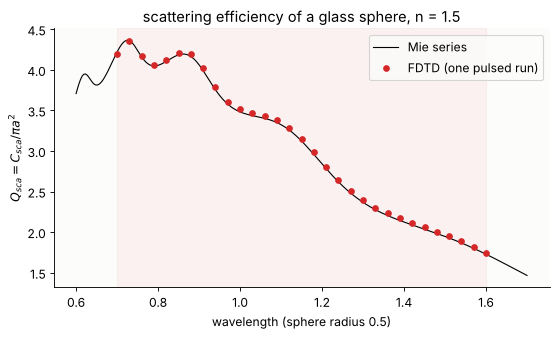

In [7]:
P_sca = sum(s*m.flux() for m, s in zip(flux1, (-1, 1)*3))
Q_fd = P_sca/(0.5*np.abs(A_cs)**2)/(np.pi*R1**2)
wl_f = np.linspace(0.6, 1.7, 300)
Q_mie = np.array([an.mie_efficiencies(R1, N1, w)[1] for w in wl_f])
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(wl_f, Q_mie, "k", lw=1, label="Mie series")
ax.plot(WLS, Q_fd, "o", ms=5, color="C3", label="FDTD (one pulsed run)")
ax.axvspan(0.7, 1.6, color="C3", alpha=0.05)
ax.set(xlabel="wavelength (sphere radius 0.5)", ylabel=r"$Q_{sca} = C_{sca}/\pi a^2$",
       title="scattering efficiency of a glass sphere, n = 1.5")
ax.legend()
Q_ref = np.array([an.mie_efficiencies(R1, N1, w)[1] for w in WLS])
print("cross section: largest deviation from Mie %.1f %%" % (100*np.max(np.abs(Q_fd/Q_ref - 1))))

The time domain: the snapshots of Ex on the plane y = 0, streamed to an
HDF5 file during the run and read back as a `SnapshotStack`. Inside the
TFSF box (dashed) the pulse passes through and is focused by the sphere,
outside it only the scattered wave travels outward.

210 frames of (70, 1, 69), 0.6 MB on disk


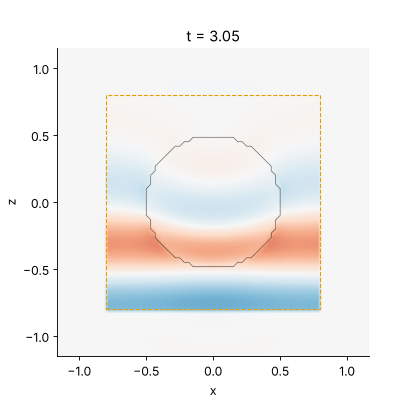

In [8]:
stack = snap1.stack()
print("%d frames of %s, %.1f MB on disk" % (len(stack), stack.frames.shape[1:], os.path.getsize(h5)/1e6))
sel = slice(int(np.searchsorted(stack.times, 3.0)), int(np.searchsorted(stack.times, 12.0)))
sub = fdtd.SnapshotStack(stack.times[sel], stack.coords, stack.frames[sel], "Ex")
fig, ax = plt.subplots(figsize=(5.2, 5))
anim = fplot.animate(sub, sim=sphere, ax=ax, vmax=1.0)
ax.add_patch(plt.Rectangle((-D, -D), 2*D, 2*D, fill=False, ec=fplot.SOURCE_COLOR, ls="--", lw=1))
gif = fplot.gif(anim, fps=12)
plt.close(fig)
gif

## 3. The photonic nanojet

A glass sphere is a ball lens (notebook 05). Ray optics puts its
paraxial focus at a distance $f = nR/(2(n - 1))$ from the centre, behind
the sphere for $n < 2$. But a sphere is a strongly aberrated lens: the
marginal rays cross the axis much closer, right behind the surface, and
together the rays form a **caustic** that starts at the paraxial focus
and reaches back to the sphere. Chen, Taflove and Backman (Opt. Express
12, 1214 (2004)) found with FDTD that for spheres a few wavelengths
across, the light concentrates in a narrow, intense **photonic nanojet**
that leaves the shadow side of the sphere, with a waist below the
wavelength and much longer than it, without any sharp focus.

The sphere here: silica, n = 1.46, diameter 4λ. First the rays:

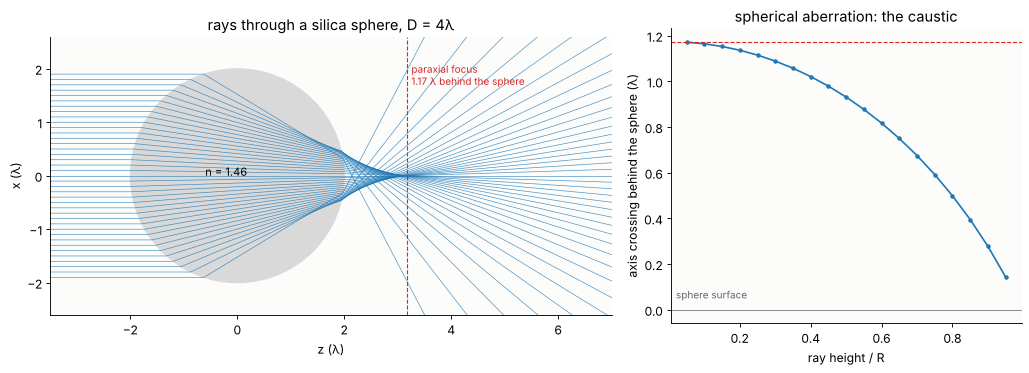

In [9]:
R2, N2 = 2.0, 1.46
f_par = N2*R2/(2*(N2 - 1))

def trace(h, z_end=7.0):
    # a ray at height h along +z through the sphere (meridional plane): points
    p = np.array([h, -R2 - 1.5])
    d = np.array([0.0, 1.0])
    pts = [p.copy()]
    for n1, n2, sgn in ((1.0, N2, -1), (N2, 1.0, 1)):
        b = p @ d
        t = -b + sgn*np.sqrt(b**2 - (p @ p - R2**2))
        p = p + t*d
        pts.append(p.copy())
        nrm = p/R2*(1 if n1 == 1.0 else -1)         # normal against the ray
        mu = n1/n2
        ci = -nrm @ d
        d = mu*d + (mu*ci - np.sqrt(1 - mu**2*(1 - ci**2)))*nrm
    pts.append(p + (z_end - p[1])/d[1]*d if d[1] > 0 else p + 3*d)
    return np.array(pts), p, d

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.6, 1]})
ax[0].add_patch(plt.Circle((0, 0), R2, color="0.85"))
hs = np.linspace(-0.95, 0.95, 39)*R2
z_cross = []
for h in hs:
    pts, p, d = trace(h)
    ax[0].plot(pts[:, 1], pts[:, 0], color="C0", lw=0.6, alpha=0.8)
    if h > 0 and d[0] < 0:
        z_cross.append((h, p[1] - p[0]*d[1]/d[0]))
ax[0].axvline(f_par, color="C3", ls="--", lw=1)
ax[0].text(f_par + 0.08, 1.7, "paraxial focus\n%.2f λ behind the sphere" % (f_par - R2), color="C3", fontsize=9)
ax[0].text(-0.6, 0.0, "n = %.2f" % N2, fontsize=10)
ax[0].set(xlim=(-3.5, 7.0), ylim=(-2.6, 2.6), aspect="equal", xlabel="z (λ)", ylabel="x (λ)",
          title="rays through a silica sphere, D = 4λ")
hc, zc = np.array(z_cross).T
ax[1].plot(hc/R2, zc - R2, "o-", ms=3)
ax[1].axhline(f_par - R2, color="C3", ls="--", lw=1)
ax[1].axhline(0, color="0.5", lw=0.8)
ax[1].text(0.02, 0.05, "sphere surface", fontsize=9, color="0.4")
ax[1].set(xlabel="ray height / R", ylabel="axis crossing behind the sphere (λ)",
          title="spherical aberration: the caustic")
plt.tight_layout()

The rays cover the axis from the paraxial focus, 1.2λ behind the
sphere, almost to its surface. Where does the light actually go? The
Mie series answers it exactly, and cheaply enough to scan the index:
the position of the brightest point on the axis behind the sphere, for
two sphere sizes, against the paraxial focus.

D = 4λ, n = 1.46: brightest point 0.14 λ behind the surface, |E|² = 46, FWHM 0.82 λ (x) and 0.44 λ (y)


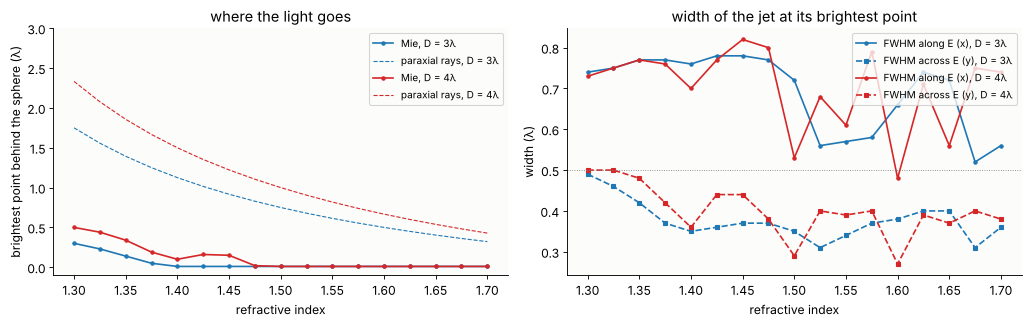

In [10]:
def jet(R, n, wl=1.0):
    # brightest point on the axis behind the sphere: distance from the surface, |E|^2, FWHM in x and y
    z = np.linspace(R + 0.01, R + 6, 600)
    I = np.sum(np.abs(an.mie_field(0*z, 0*z, z, R, n, wl))**2, axis=0)
    k = np.argmax(I)
    s = np.linspace(-1.5, 1.5, 601)
    Ix = np.sum(np.abs(an.mie_field(s, 0*s, z[k] + 0*s, R, n, wl))**2, axis=0)
    Iy = np.sum(np.abs(an.mie_field(0*s, s, z[k] + 0*s, R, n, wl))**2, axis=0)
    fw = lambda v: np.ptp(s[v > v.max()/2])
    return z[k] - R, I[k], fw(Ix), fw(Iy)

ns = np.linspace(1.3, 1.7, 17)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for R, c in ((1.5, "C0"), (2.0, "C3")):
    res = np.array([jet(R, n) for n in ns])
    ax[0].plot(ns, res[:, 0], "o-", ms=3, color=c, label="Mie, D = %gλ" % (2*R))
    ax[0].plot(ns, ns*R/(2*(ns - 1)) - R, "--", color=c, lw=1, label="paraxial rays, D = %gλ" % (2*R))
    ax[1].plot(ns, res[:, 2], "o-", ms=3, color=c, label="FWHM along E (x), D = %gλ" % (2*R))
    ax[1].plot(ns, res[:, 3], "s--", ms=3, color=c, label="FWHM across E (y), D = %gλ" % (2*R))
ax[0].set(xlabel="refractive index", ylabel="brightest point behind the sphere (λ)", ylim=(-0.1, 3),
          title="where the light goes")
ax[0].legend(fontsize=9)
ax[1].axhline(0.5, color="0.5", lw=0.8, ls=":")
ax[1].set(xlabel="refractive index", ylabel="width (λ)", title="width of the jet at its brightest point")
ax[1].legend(fontsize=9)
plt.tight_layout()
jet_dz, jet_I, jet_fx, jet_fy = jet(R2, N2)
print("D = 4λ, n = 1.46: brightest point %.2f λ behind the surface, |E|² = %.0f, FWHM %.2f λ (x) and %.2f λ (y)"
      % (jet_dz, jet_I, jet_fx, jet_fy))

Two things ray optics cannot say. The intensity peaks at the surface or
a few tenths of a wavelength behind it, not at the paraxial focus; from
an index of about 1.4 (D = 3λ) or 1.5 (D = 4λ) on it sits right on the
surface, and only weakly refracting spheres push the jet further out. And the jet is not round: across the polarization (y) it is
about half a wavelength wide or less, along the polarization (x) almost
twice as wide. The field along x has a longitudinal component Ez at the
edges of the spot, which a scalar theory has no room for.

Now the full 3D FDTD run of the silica sphere, D = 4λ, with DFT planes
through the axis (y = 0, along E, and x = 0, across E) and across the
jet at its brightest point:

Grid(shape=(180, 180, 246), spacing=(np.float64(0.03333333333333333), np.float64(0.03333333333333333), np.float64(0.03333333333333333)), origin=(np.float64(-3.0), np.float64(-3.0), np.float64(-2.9999999999999996))) 8.0 million cells


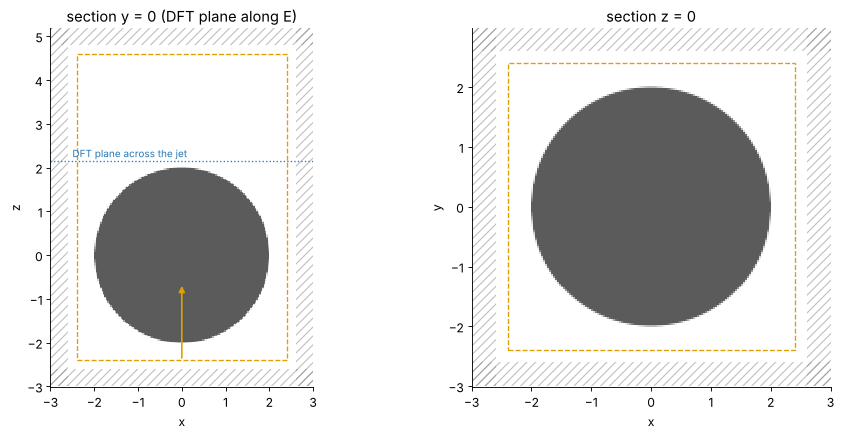

In [11]:
H2 = 1/30
z_jet = R2 + jet_dz
P2 = 12*H2
box2 = (-2.4, 2.4, -2.4, 2.4, -2.4, 4.6)
grid2 = fdtd.Grid((4.8 + 0.4 + 2*P2, 4.8 + 0.4 + 2*P2, 7.0 + 0.4 + 2*P2), H2, center=(0, 0, 1.1))
src2 = fdtd.TFSF(box2, fdtd.GaussianPulse(1.0, 0.15), wavelengths=[1.0])
along = fdtd.DFTField(1.0, components=["Ex", "Ey", "Ez"], region=((-2.3, 2.3), 0.0, (-2.3, 4.5)))
across = fdtd.DFTField(1.0, components=["Ex", "Ey", "Ez"], region=(0.0, (-2.3, 2.3), (-2.3, 4.5)))
waist = fdtd.DFTField(1.0, components=["Ex", "Ey", "Ez"], region=((-1.5, 1.5), (-1.5, 1.5), z_jet))
nanojet = fdtd.Simulation(grid2, [(fdtd.Sphere((0, 0, 0), R2), fdtd.Medium.from_index(N2))],
                          [src2], [along, across, waist], boundaries=fdtd.PML(12))
print(grid2, "%.1f million cells" % (np.prod(grid2.shape)/1e6))
fig, ax = plt.subplots(1, 2, figsize=(12, 5.6), gridspec_kw={"width_ratios": [1, 1.2]})
fplot.plot_structure(nanojet, ax=ax[0])
ax[0].axhline(z_jet, color=fplot.MONITOR_COLOR, ls=":", lw=1.2)
ax[0].text(-2.5, z_jet + 0.1, "DFT plane across the jet", color=fplot.MONITOR_COLOR, fontsize=9)
ax[0].set_title("section y = 0 (DFT plane along E)")
fplot.plot_structure(nanojet, ax=ax[1], plane=("z", 0.0))
ax[1].set_title("section z = 0")
plt.tight_layout()

In [12]:
nanojet.run(time=40, progress=True)
z0 = nanojet.grid.axis(2)[src2.box_indices[4]]
A2 = (src2.incident_phasor(z0)*np.exp(-2j*np.pi*z0))[0]

2100 steps in 184.26 s (90.8 Mcell updates/s)


The comparison: $|\mathbf E|^2$ on the two planes through the axis, FDTD
against Mie. Behind the sphere, the jet: narrow in the plane across E
(right), wider in the plane along E (left). Inside the sphere, the
interference of the light refracted at the front and reflected at the
back surface.

plane y = 0: |E|² deviation from Mie 8.7 % (rms over the plane, relative)
plane x = 0: |E|² deviation from Mie 8.4 % (rms over the plane, relative)


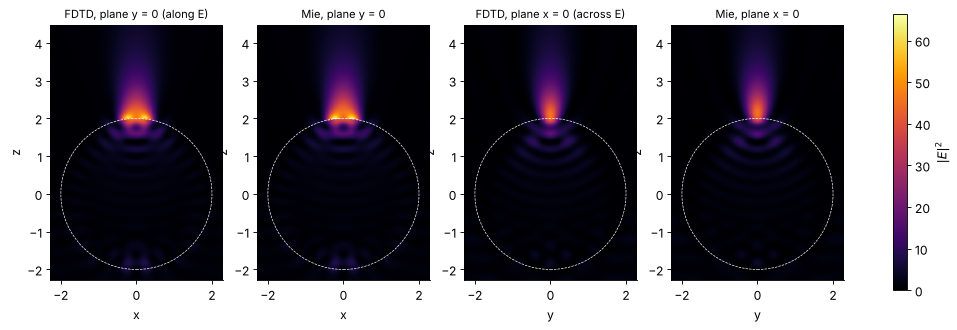

In [13]:
def planes(dft, axis):
    crd, E = dft.colocated(["Ex", "Ey", "Ez"])
    I = np.sum(np.abs(np.take(E, 0, axis=axis + 1)/A2)**2, axis=0)
    s, z = [c for a, c in enumerate(crd) if a != axis]
    S, Z = np.meshgrid(s, z, indexing="ij")
    pts = [S, 0*S, Z] if axis == 1 else [0*S, S, Z]
    return s, z, I, np.sum(np.abs(an.mie_field(*pts, R2, N2, 1.0))**2, axis=0)

xa, za, I_a, M_a = planes(along, 1)
ya, zb, I_b, M_b = planes(across, 0)
vmax = M_a.max()
fig, ax = plt.subplots(1, 4, figsize=(16, 6.4))
for a, s, z, V, t in ((ax[0], xa, za, I_a, "FDTD, plane y = 0 (along E)"),
                      (ax[1], xa, za, M_a, "Mie, plane y = 0"),
                      (ax[2], ya, zb, I_b, "FDTD, plane x = 0 (across E)"),
                      (ax[3], ya, zb, M_b, "Mie, plane x = 0")):
    im = a.imshow(V.T, origin="lower", extent=fplot._extent([s, z]), cmap="inferno", vmin=0, vmax=vmax)
    a.add_patch(plt.Circle((0, 0), R2, fill=False, ec="w", lw=0.6, ls="--"))
    a.set(xlabel="x" if a in ax[:2] else "y", ylabel="z", title=t)
    a.title.set_fontsize(10)
plt.colorbar(im, ax=ax, shrink=0.7, label=r"$|E|^2$")
for name, I, M in (("y = 0", I_a, M_a), ("x = 0", I_b, M_b)):
    print("plane %s: |E|² deviation from Mie %.1f %% (rms over the plane, relative)"
          % (name, 100*np.sqrt(np.sum((I - M)**2)/np.sum(M**2))))

The FDTD maps agree with the series to about 9 % rms over the planes, at
20 cells per wavelength in the glass; the jet itself, its position, peak
and width, agrees to a few percent (below). Across the jet, at its brightest point: the spot is an ellipse, long
along the polarization.

FWHM along E: 0.82 λ (FDTD), 0.82 λ (Mie); across E: 0.45 λ (FDTD), 0.44 λ (Mie)


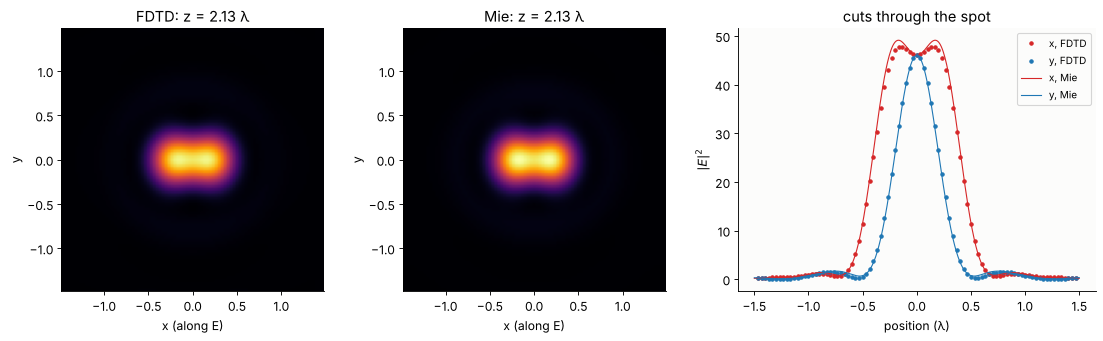

In [14]:
(xw, yw, _), Ew = waist.colocated(["Ex", "Ey", "Ez"])
I_w = np.sum(np.abs(Ew[:, :, :, 0]/A2)**2, axis=0)
Xw, Yw = np.meshgrid(xw, yw, indexing="ij")
z_node = waist.coords("Ex")[2][0]
M_w = np.sum(np.abs(an.mie_field(Xw, Yw, z_node + 0*Xw, R2, N2, 1.0))**2, axis=0)
fig, ax = plt.subplots(1, 3, figsize=(14, 4.4), gridspec_kw={"width_ratios": [1, 1, 1.3]})
for a, V, t in ((ax[0], I_w, "FDTD"), (ax[1], M_w, "Mie")):
    a.imshow(V.T, origin="lower", extent=fplot._extent([xw, yw]), cmap="inferno", vmin=0, vmax=M_w.max())
    a.set(xlabel="x (along E)", ylabel="y", title="%s: z = %.2f λ" % (t, z_node))
i0, j0_ = np.argmin(np.abs(xw)), np.argmin(np.abs(yw))
s_f = np.linspace(-1.5, 1.5, 601)
for V, s, c, lab in ((I_w[:, j0_], xw, "C3", "x, FDTD"), (I_w[i0], yw, "C0", "y, FDTD")):
    ax[2].plot(s, V, "o", ms=3, color=c, label=lab)
ax[2].plot(s_f, np.sum(np.abs(an.mie_field(s_f, 0*s_f, z_node + 0*s_f, R2, N2, 1.0))**2, 0), color="C3",
           lw=1, label="x, Mie")
ax[2].plot(s_f, np.sum(np.abs(an.mie_field(0*s_f, s_f, z_node + 0*s_f, R2, N2, 1.0))**2, 0), color="C0",
           lw=1, label="y, Mie")
ax[2].set(xlabel="position (λ)", ylabel=r"$|E|^2$", title="cuts through the spot")
ax[2].legend(fontsize=9)
plt.tight_layout()

def fwhm(s, v):
    fine = np.linspace(s[0], s[-1], 4001)
    vf = np.interp(fine, s, v)
    return np.ptp(fine[vf > vf.max()/2])
print("FWHM along E: %.2f λ (FDTD), %.2f λ (Mie); across E: %.2f λ (FDTD), %.2f λ (Mie)"
      % (fwhm(xw, I_w[:, j0_]), jet_fx, fwhm(yw, I_w[i0]), jet_fy))

Finally, the scalar models of notebook 05 on the axis. The **scalar sphere
series** (`sphere_field`) solves the Helmholtz equation exactly, but for a
scalar field: it has no polarization and no longitudinal component. The
**WPM** steps a scalar field through the sphere in thin slices, without
reflections. Both are lit by the same plane wave (the WPM by a flat top
6λ wide, to keep the edges of its periodic window dark).

WPM: 140 steps on 384x384 in 3.6 s
brightest point behind the sphere: Mie 0.14, scalar series 0.01, WPM 0.15 λ from the surface, paraxial rays 1.17
peak |E|²: Mie 46, FDTD 47, scalar series 78, WPM 43


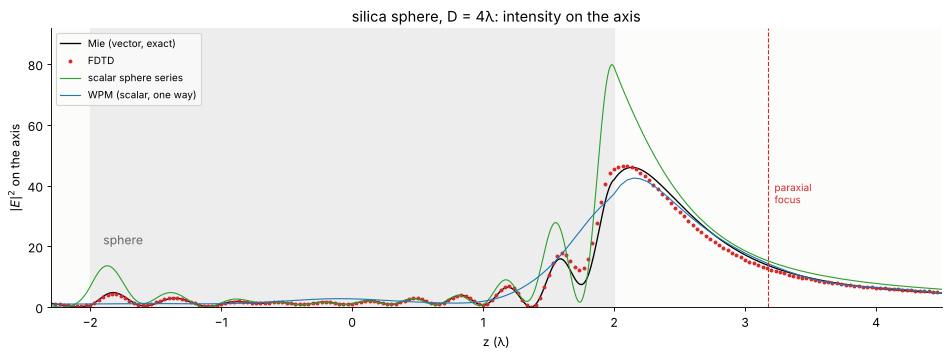

In [15]:
# WPM through the sphere with 2D fields: keep the axis
Lw, Nw, dzw = 12.0, 384, 0.05
xw_ = grid1d(-Lw/2, Lw/2, Nw)
Xq, Yq = np.meshgrid(xw_, xw_)
u = np.exp(-(np.hypot(Xq, Yq)/3.0)**12).astype(complex)
n_ball = lambda X, Y, z: np.where(X**2 + Y**2 + z**2 < R2**2, N2, 1.0)
z_w = np.arange(-R2 - 0.5, 4.5 + 1e-9, dzw)
axis_wpm = [np.abs(u[Nw//2, Nw//2])**2]
t0 = time.perf_counter()
for k in range(1, len(z_w)):
    u = wpm_propagate(n_ball, u, xw_, xw_, z_w[k - 1], dzw, 1.0)
    axis_wpm.append(np.abs(u[Nw//2, Nw//2])**2)
print("WPM: %d steps on %dx%d in %.1f s" % (len(z_w) - 1, Nw, Nw, time.perf_counter() - t0))

z_ax = np.linspace(-2.3, 4.5, 700)
I_mie_ax = np.sum(np.abs(an.mie_field(0*z_ax, 0*z_ax, z_ax, R2, N2, 1.0))**2, axis=0)
I_sc_ax = np.abs(an.sphere_field(0*z_ax, z_ax, R2, N2, 1.0))**2
i_ax = np.argmin(np.abs(xa))
fig, ax = plt.subplots(figsize=(12, 4.6))
ax.axvspan(-R2, R2, color="0.93", zorder=-1)
ax.plot(z_ax, I_mie_ax, "k", lw=1.2, label="Mie (vector, exact)")
ax.plot(za, I_a[i_ax], "o", ms=2.5, color="C3", label="FDTD")
ax.plot(z_ax, I_sc_ax, color="C2", lw=1, label="scalar sphere series")
ax.plot(z_w, axis_wpm, color="C0", lw=1, label="WPM (scalar, one way)")
ax.axvline(f_par, color="C3", ls="--", lw=1)
ax.text(f_par + 0.05, 0.9*I_mie_ax.max(), "paraxial\nfocus", color="C3", fontsize=9, va="top")
ax.set(xlabel="z (λ)", ylabel=r"$|E|^2$ on the axis", xlim=(-2.3, 4.5),
       title="silica sphere, D = 4λ: intensity on the axis")
ax.text(-1.9, 0.45*I_mie_ax.max(), "sphere", color="0.4")
ax.set_ylim(0, 1.15*max(np.max(I_sc_ax), I_mie_ax.max()))
ax.legend(loc="upper left", fontsize=9)
plt.tight_layout()
k_m = np.argmax(np.where(z_ax > R2, I_mie_ax, 0))
k_w = np.argmax(np.where(z_w > R2, axis_wpm, 0))
k_s = np.argmax(np.where(z_ax > R2, I_sc_ax, 0))
print("brightest point behind the sphere: Mie %.2f, scalar series %.2f, WPM %.2f λ from the surface, "
      "paraxial rays %.2f" % (z_ax[k_m] - R2, z_ax[k_s] - R2, z_w[k_w] - R2, f_par - R2))
print("peak |E|²: Mie %.0f, FDTD %.0f, scalar series %.0f, WPM %.0f"
      % (I_mie_ax[k_m], np.max(np.where(za > R2, I_a[i_ax], 0)), I_sc_ax[k_s], axis_wpm[k_w]))

FDTD follows the vector Mie series along the whole axis. All wave models
pull the brightest point from the paraxial focus to the surface of the
sphere, but the scalar series overshoots the peak by more than half: for
a scalar field the waves converging on the axis from all sides add up
like parallel vectors, while the true fields arriving from the sides
along x are tilted against each other and add up only partly (the same
effect that widens the spot along E). The WPM lands close to the vector
peak only by chance: as for the ball lens of notebook 05, it loses part
of the light refracted steeply near the rim, which lowers its scalar
peak; and having no reflections, it misses the light reflected at the
back surface inside the sphere.

## 4. Working in 3D

- `Grid((Lx, Ly, Lz), h)` makes the simulation 3D; the polarization mode
  is then "3D" and all six components are updated. The defaults change
  with it: float32 fields and the numba kernels.
- 3D shapes: `Sphere`, `Box`, `Cylinder` and `Prism`, which extrudes any
  2D shape (`Prism(fdtd.Path(...), z0, z1)` is a strip waveguide,
  `Prism(fdtd.Circle(...), ...)` a pillar); `Slab` works in any dimension.
- Sources: `PointSource` (any component), `PlaneSource` (a current sheet,
  with Bloch phases for oblique incidence), `TFSF` (a plane wave along +z,
  polarized along x or y, with `wavelengths=` for the incident spectrum).
- Monitors: a number instead of a range in a region picks one node layer,
  so `DFTField(wls, region=(None, 0.0, None))` records the plane y = 0;
  `colocated()` moves the components to common nodes; `Flux` works on
  planes; `Snapshots(path="....h5")` streams frames to HDF5.
- Plots show sections: `plot_structure(sim, plane=("z", 0.0))`; monitors
  on a single plane are shown as they are.

## Summary

- The 3D Yee scheme updates six components on a staggered cell; the numba
  kernels reach about 90 million cell updates per second on four cores in
  float32.
- A sphere one wavelength across matches the vector Mie series
  (`analytical.mie_field`, new here) to 1 to 3 % away from the surface at
  30 cells per vacuum wavelength, and its scattering cross section over the
  whole band of one pulse to about a percent.
- A glass microsphere a few wavelengths across concentrates light in a
  photonic nanojet right behind its surface, far closer than the paraxial
  focus of ray optics; the jet is half a wavelength wide across the
  polarization and about twice that along it, which only the vector
  solutions (FDTD and Mie) show.

Next (proposals/fdtd.md): the litho mask model, rigorous 3D mask
features handed to the imaging code.

In [16]:
print("total run time of this notebook: %.1f min" % ((time.perf_counter() - t_start)/60))

total run time of this notebook: 4.3 min
